# Text-to-Speech and Speech-to-Text on Scripture Text

This notebook covers:

1. **4 sophisticated models**, all loaded through the `transformers` library:
   - Text-to-speech: **MMS-TTS** (Meta, VITS-based) and **Bark** (Suno, transformer-based)
   - Speech-to-text: **Whisper** (OpenAI) and **MMS-ASR** (Meta, wav2vec 2.0-based)
2. **2 languages**: English and Hindi
3. **4 performance metrics**: WER, CER, BLEU, RTF
4. **Corpus**: 12 King James Bible verses (English) and 12 Bhagavad Gita verses (Hindi)

Pipeline tested: scripture text → TTS → audio → STT → transcribed text, for **every
TTS × STT pairing** (2 × 2 = 4 pairings). Transcribed text is scored against the original.

**Use a GPU runtime** (Runtime → Change runtime type → T4 GPU). Bark is very slow on CPU.


## 0. Setup

Install the required libraries. First run takes a few minutes.

In [13]:
!pip install -q transformers accelerate torch torchaudio
!pip install -q soundfile librosa
!pip install -q jiwer sacrebleu


In [14]:
import re
import time
import unicodedata
import numpy as np
import pandas as pd
import torch
import librosa
import matplotlib.pyplot as plt
from IPython.display import Audio, display

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
torch.manual_seed(0)


Device: cuda


## 1. Corpus: Scripture Text

**English** — 12 verses from the King James Bible (public domain, 1611), spanning
several books for lexical variety.

**Hindi** — 12 verses from the Bhagavad Gita. The Sanskrit original is ancient and
public domain; the Hindi text below is translated here directly from that Sanskrit,
rather than copied from any single published translator's copyrighted wording.

Each line carries its source reference, so results can be traced back to a specific
verse.


In [15]:
corpus = {
    "eng": [
        ("In the beginning God created the heaven and the earth.", "Genesis 1:1"),
        ("And God said, Let there be light: and there was light.", "Genesis 1:3"),
        ("Thou shalt have no other gods before me.", "Exodus 20:3"),
        ("The Lord is my shepherd; I shall not want.", "Psalm 23:1"),
        ("God is our refuge and strength, a very present help in trouble.", "Psalm 46:1"),
        ("The fear of the Lord is the beginning of knowledge.", "Proverbs 1:7"),
        ("To every thing there is a season, and a time to every purpose under the heaven.", "Ecclesiastes 3:1"),
        ("But they that wait upon the Lord shall renew their strength.", "Isaiah 40:31"),
        ("In the beginning was the Word, and the Word was with God, and the Word was God.", "John 1:1"),
        ("For God so loved the world, that he gave his only begotten Son.", "John 3:16"),
        ("Blessed are the peacemakers: for they shall be called the children of God.", "Matthew 5:9"),
        ("And we know that all things work together for good to them that love God.", "Romans 8:28"),
    ],
    "hin": [
        ("आत्मा न कभी जन्म लेती है, न कभी मरती है।", "Gita 2.20"),
        ("हे कुंतीपुत्र, सर्दी-गर्मी और सुख-दुःख इंद्रियों के विषयों से उत्पन्न होते हैं।", "Gita 2.14"),
        ("तुम्हारा अधिकार केवल कर्म करने में है, उसके फल में कभी नहीं।", "Gita 2.47"),
        ("हे अर्जुन, आसक्ति को त्यागकर और योग में स्थित होकर कर्म करो।", "Gita 2.48"),
        ("समबुद्धि वाला व्यक्ति इस जीवन में पाप और पुण्य दोनों को त्याग देता है।", "Gita 2.50"),
        ("अपना धर्म, भले ही अपूर्ण हो, दूसरे के धर्म से श्रेष्ठ है।", "Gita 3.35"),
        ("हे भारत, जब-जब धर्म की हानि होती है, तब-तब मैं प्रकट होता हूँ।", "Gita 4.7"),
        ("साधुओं की रक्षा और दुष्टों के विनाश के लिए मैं युग-युग में जन्म लेता हूँ।", "Gita 4.8"),
        ("मनुष्य को स्वयं अपने बल से अपना उद्धार करना चाहिए, स्वयं को कभी गिरने नहीं देना चाहिए।", "Gita 6.5"),
        ("अभ्यास और वैराग्य से मन को वश में किया जा सकता है।", "Gita 6.35"),
        ("क्रोध से मोह उत्पन्न होता है, और मोह से बुद्धि नष्ट हो जाती है।", "Gita 2.63"),
        ("सभी कर्तव्यों को छोड़कर केवल मेरी शरण में आ जाओ।", "Gita 18.66"),
    ],
}

for lang, items in corpus.items():
    print(f"[{lang}] {len(items)} lines")
    for text, ref in items[:3]:
        print(f"  ({ref}) {text}")
    print("  ...\n")


[eng] 12 lines
  (Genesis 1:1) In the beginning God created the heaven and the earth.
  (Genesis 1:3) And God said, Let there be light: and there was light.
  (Exodus 20:3) Thou shalt have no other gods before me.
  ...

[hin] 12 lines
  (Gita 2.20) आत्मा न कभी जन्म लेती है, न कभी मरती है।
  (Gita 2.14) हे कुंतीपुत्र, सर्दी-गर्मी और सुख-दुःख इंद्रियों के विषयों से उत्पन्न होते हैं।
  (Gita 2.47) तुम्हारा अधिकार केवल कर्म करने में है, उसके फल में कभी नहीं।
  ...



## 2. Text-to-Speech Models

**TTS Model 1 — MMS-TTS (Meta).** One VITS checkpoint per language: a flow-based,
end-to-end text-to-waveform model with no separate vocoder. Small and fast.

**TTS Model 2 — Bark (Suno).** A multilingual transformer that generates audio tokens
in three stages (semantic → coarse → fine) and decodes them with EnCodec. One
checkpoint for all languages, with a speaker preset chosen per language. Larger and
slower, and generation is sampled rather than deterministic.


In [16]:
from transformers import VitsModel, AutoTokenizer, AutoProcessor, BarkModel

# ---- TTS 1: MMS-TTS (one checkpoint per language) ----
MMS_TTS_CHECKPOINTS = {"eng": "facebook/mms-tts-eng", "hin": "facebook/mms-tts-hin"}
mms_tts = {}
for lang, name in MMS_TTS_CHECKPOINTS.items():
    tok = AutoTokenizer.from_pretrained(name)
    mdl = VitsModel.from_pretrained(name).to(device).eval()
    mms_tts[lang] = (tok, mdl)

def synth_mms(text, lang):
    tok, mdl = mms_tts[lang]
    inputs = tok(text, return_tensors="pt").to(device)
    start = time.time()
    with torch.no_grad():
        wav = mdl(**inputs).waveform
    elapsed = time.time() - start
    return wav.squeeze().cpu().numpy().astype(np.float32), mdl.config.sampling_rate, elapsed

# ---- TTS 2: Bark (one checkpoint, speaker preset per language) ----
bark_processor = AutoProcessor.from_pretrained("suno/bark-small")
bark_model = BarkModel.from_pretrained("suno/bark-small").to(device).eval()
BARK_VOICE = {"eng": "v2/en_speaker_6", "hin": "v2/hi_speaker_2"}

def synth_bark(text, lang):
    inputs = bark_processor(text, voice_preset=BARK_VOICE[lang]).to(device)
    start = time.time()
    with torch.no_grad():
        wav = bark_model.generate(**inputs)
    elapsed = time.time() - start
    sr = bark_model.generation_config.sample_rate
    return wav.squeeze().cpu().numpy().astype(np.float32), sr, elapsed

TTS_MODELS = {"MMS-TTS": synth_mms, "Bark": synth_bark}
print("TTS models loaded:", list(TTS_MODELS))


Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/542 [00:00<?, ?it/s]

TTS models loaded: ['MMS-TTS', 'Bark']


In [17]:
# Quick listen: first verse, each TTS model, each language
demo_audio = {}
for tts_name, synth in TTS_MODELS.items():
    for lang, items in corpus.items():
        text, ref = items[0]
        audio, sr, elapsed = synth(text, lang)
        demo_audio[(tts_name, lang)] = (audio, sr)
        print(f"[{tts_name} | {lang}] ({ref}) {len(audio)/sr:.2f}s of audio in {elapsed:.2f}s")
        display(Audio(audio, rate=sr))


[MMS-TTS | eng] (Genesis 1:1) 3.94s of audio in 0.26s


[MMS-TTS | hin] (Gita 2.20) 4.10s of audio in 0.13s


[transformers] Both `max_new_tokens` (=768) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/doc

[Bark | eng] (Genesis 1:1) 10.68s of audio in 73.52s


[transformers] Both `max_new_tokens` (=768) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/doc

[Bark | hin] (Gita 2.20) 4.55s of audio in 11.02s


## 3. Speech-to-Text Models

**STT Model 1 — Whisper (OpenAI).** A single multilingual encoder-decoder transformer
trained on 680,000 hours of weakly supervised web audio. One checkpoint for all
languages; the decoding language is forced per verse. Output is cased and punctuated.

**STT Model 2 — MMS-ASR (Meta).** A wav2vec 2.0 encoder with a CTC output layer and a
small per-language adapter (`eng`, `hin`). Character-level output, no punctuation.

Whisper and MMS-ASR write text differently (case, punctuation), so **all text is
normalised before scoring** — lower-cased, punctuation removed — so the metrics compare
words, not formatting.


In [18]:
from transformers import pipeline, Wav2Vec2ForCTC

# ---- STT 1: Whisper ----
asr_whisper = pipeline(
    "automatic-speech-recognition",
    model="openai/whisper-small",
    device=0 if device == "cuda" else -1,
)
WHISPER_LANGUAGE = {"eng": "english", "hin": "hindi"}

def stt_whisper(audio_16k, lang):
    start = time.time()
    out = asr_whisper(
        {"array": audio_16k, "sampling_rate": 16000},
        generate_kwargs={"language": WHISPER_LANGUAGE[lang], "task": "transcribe"},
    )
    return out["text"].strip(), time.time() - start

# ---- STT 2: MMS-ASR (wav2vec 2.0 + CTC, per-language adapter) ----
mms_asr_processor = AutoProcessor.from_pretrained("facebook/mms-1b-all")
mms_asr_model = Wav2Vec2ForCTC.from_pretrained("facebook/mms-1b-all").to(device).eval()

def stt_mms(audio_16k, lang):
    mms_asr_processor.tokenizer.set_target_lang(lang)   # "eng" / "hin"
    mms_asr_model.load_adapter(lang)
    inputs = mms_asr_processor(audio_16k, sampling_rate=16000, return_tensors="pt").to(device)
    start = time.time()
    with torch.no_grad():
        logits = mms_asr_model(**inputs).logits
    elapsed = time.time() - start
    ids = torch.argmax(logits, dim=-1)[0]
    return mms_asr_processor.decode(ids).strip(), elapsed

STT_MODELS = {"Whisper": stt_whisper, "MMS-ASR": stt_mms}

def to_16k(audio, sr):
    return librosa.resample(audio, orig_sr=sr, target_sr=16000) if sr != 16000 else audio

def normalize(text):
    """Lower-case and replace punctuation/symbols with spaces (works for Devanagari too)."""
    text = unicodedata.normalize("NFC", text).lower()
    text = "".join(" " if unicodedata.category(ch)[0] in "PS" else ch for ch in text)
    return " ".join(text.split())

print("STT models loaded:", list(STT_MODELS))


Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/1096 [00:00<?, ?it/s]

STT models loaded: ['Whisper', 'MMS-ASR']


In [19]:
# Quick check: first verse, every TTS x STT pairing, both languages
for lang, items in corpus.items():
    text, ref = items[0]
    print(f"[{lang}] ({ref}) original: {text}")
    for tts_name, synth in TTS_MODELS.items():
        audio, sr, _ = synth(text, lang)
        audio_16k = to_16k(audio, sr)
        for stt_name, stt in STT_MODELS.items():
            hyp, _ = stt(audio_16k, lang)
            print(f"   {tts_name} -> {stt_name}: {hyp}")
    print()


[eng] (Genesis 1:1) original: In the beginning God created the heaven and the earth.
   MMS-TTS -> Whisper: In the beginning, God created the heaven and the earth.


[transformers] Both `max_new_tokens` (=768) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


   MMS-TTS -> MMS-ASR: in the beginning god greated the heaven and the earth


[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs

   Bark -> Whisper: In the beginning, God created the heaven and the earth.
   Bark -> MMS-ASR: in the beginning god created the heaven in the earth

[hin] (Gita 2.20) original: आत्मा न कभी जन्म लेती है, न कभी मरती है।
   MMS-TTS -> Whisper: आत्मा नक भी जन लेती है, नक भी मरती है


[transformers] Both `max_new_tokens` (=768) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


   MMS-TTS -> MMS-ASR: आत्मा न कभी जन लेती है न कभी मरती है


[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs

   Bark -> Whisper: आप्मा ना कभी जन लेती है, ना कभी मरती है.
   Bark -> MMS-ASR: आपमाना कभी जन्म लेती है न कभी मरती है



## 4. Full Round Trip: Text → TTS → Audio → STT → Text

Each verse is synthesised once per TTS model, and each resulting audio clip is then
transcribed by both STT models. That gives 2 TTS × 2 STT × 24 verses = **96 round
trips**. Timings are kept for the RTF metric. Expect several minutes on a T4 GPU
(Bark dominates the time).


In [20]:
records = []

for tts_name, synth in TTS_MODELS.items():
    for lang, items in corpus.items():
        for text, ref in items:
            audio, sr, tts_time = synth(text, lang)
            duration = len(audio) / sr
            audio_16k = to_16k(audio, sr)
            for stt_name, stt in STT_MODELS.items():
                hyp, stt_time = stt(audio_16k, lang)
                records.append({
                    "tts": tts_name, "stt": stt_name, "lang": lang, "ref": ref,
                    "original": text, "transcribed": hyp,
                    "tts_time": tts_time, "stt_time": stt_time,
                    "audio_duration": duration,
                })

records_df = pd.DataFrame(records)
records_df["pair"] = records_df["tts"] + " → " + records_df["stt"]
print(f"Processed {len(records_df)} round trips.")


[transformers] Both `max_new_tokens` (=768) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/doc

Processed 96 round trips.


In [21]:
# Sample: the first verse of each language, across all four pairings
first_refs = [items[0][1] for items in corpus.values()]
records_df[records_df["ref"].isin(first_refs)][["lang", "pair", "original", "transcribed"]]


,lang,pair,original,transcribed
0,eng,MMS-TTS → Whisper,In the beginning God created the heaven and th...,In the beginning God created the heaven and th...
1,eng,MMS-TTS → MMS-ASR,In the beginning God created the heaven and th...,in the beginning god created the heaven and th...
24,hin,MMS-TTS → Whisper,"आत्मा न कभी जन्म लेती है, न कभी मरती है।","आत्मान नकभी जन नेती है, नकभी मरती है"
25,hin,MMS-TTS → MMS-ASR,"आत्मा न कभी जन्म लेती है, न कभी मरती है।",आत्मान न कभी जन लेती है न कभी मरती है
48,eng,Bark → Whisper,In the beginning God created the heaven and th...,In the beginning God created the heaven and th...
49,eng,Bark → MMS-ASR,In the beginning God created the heaven and th...,in the beginning god created the heaven and th...
72,hin,Bark → Whisper,"आत्मा न कभी जन्म लेती है, न कभी मरती है।",आत्मन कभी जन लेती हैं आत्मन कभी मटी हैं
73,hin,Bark → MMS-ASR,"आत्मा न कभी जन्म लेती है, न कभी मरती है।",आक मन कभी जन्मलइती है न कभी मटे हैं


## 5. Performance Metrics

| Metric | Measures | Range |
|---|---|---|
| **WER** | word-level edit distance, original vs. transcribed | 0+, lower is better |
| **CER** | character-level edit distance | 0+, lower is better |
| **BLEU** | n-gram overlap, original vs. transcribed | 0–100, higher is better |
| **RTF** | processing time ÷ audio duration | lower is faster than real time |

WER, CER and BLEU measure round-trip intelligibility for each TTS → STT pairing (text
normalised first). RTF measures speed: for TTS it is synthesis time ÷ audio duration,
for STT it is transcription time ÷ audio duration. All are computed per language over
the 12 verses.


In [22]:
import jiwer
import sacrebleu

def pair_metrics(g):
    refs = [normalize(t) for t in g["original"]]
    hyps = [normalize(t) for t in g["transcribed"]]
    return pd.Series({
        "WER": round(jiwer.wer(refs, hyps), 4),
        "CER": round(jiwer.cer(refs, hyps), 4),
        "BLEU": round(sacrebleu.corpus_bleu(hyps, [refs]).score, 2),
        "n_lines": len(g),
    })

quality_df = (records_df.groupby(["lang", "tts", "stt"])
              .apply(pair_metrics, include_groups=False))
quality_df


WER     CER   BLEU  n_lines
lang tts     stt                                    
eng  Bark    MMS-ASR  0.1034  0.0478  83.05     12.0
             Whisper  0.1310  0.0914  81.95     12.0
     MMS-TTS MMS-ASR  0.0552  0.0183  90.17     12.0
             Whisper  0.0345  0.0127  93.11     12.0
hin  Bark    MMS-ASR  0.4241  0.1804  37.30     12.0
             Whisper  0.6076  0.2837   9.45     12.0
     MMS-TTS MMS-ASR  0.1646  0.0661  66.03     12.0
             Whisper  0.4051  0.1543  33.88     12.0

In [23]:
# RTF: speed of each model, per language.
# TTS time is measured once per (tts, verse), so drop the duplicate rows from the STT loop.
tts_once = records_df.drop_duplicates(subset=["tts", "lang", "ref"])
tts_rtf = (tts_once.groupby(["tts", "lang"])
           .apply(lambda g: round(g["tts_time"].sum() / g["audio_duration"].sum(), 3),
                  include_groups=False).unstack())
stt_rtf = (records_df.groupby(["stt", "lang"])
           .apply(lambda g: round(g["stt_time"].sum() / g["audio_duration"].sum(), 3),
                  include_groups=False).unstack())

print("TTS real-time factor (synthesis time / audio duration):")
display(tts_rtf)
print("STT real-time factor (transcription time / audio duration):")
display(stt_rtf)


TTS real-time factor (synthesis time / audio duration):


lang,eng,hin
tts,,
Bark,2.589,2.468
MMS-TTS,0.016,0.023


STT real-time factor (transcription time / audio duration):


lang,eng,hin
stt,,
MMS-ASR,0.009,0.014
Whisper,0.100,0.349


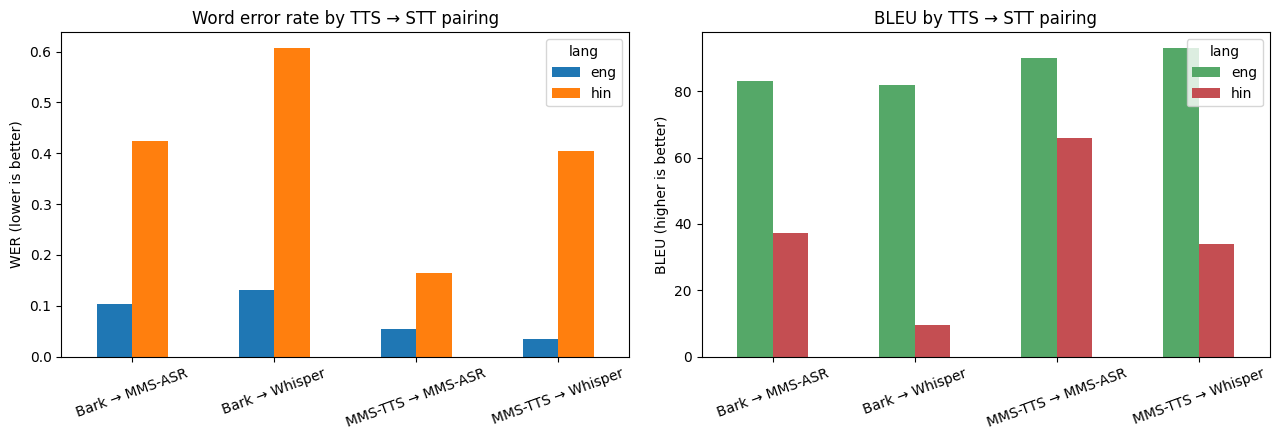

In [24]:
pivot_wer = quality_df["WER"].unstack("lang")
pivot_bleu = quality_df["BLEU"].unstack("lang")
labels = [f"{t} → {s}" for t, s in pivot_wer.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

pivot_wer.set_axis(labels).plot(kind="bar", ax=axes[0], rot=20)
axes[0].set_ylabel("WER (lower is better)")
axes[0].set_title("Word error rate by TTS → STT pairing")

pivot_bleu.set_axis(labels).plot(kind="bar", ax=axes[1], rot=20, color=["#55a868", "#c44e52"])
axes[1].set_ylabel("BLEU (higher is better)")
axes[1].set_title("BLEU by TTS → STT pairing")

plt.tight_layout()
plt.show()


## 6. Visual analysis

These charts show **where** the errors come from, not only how many there are.

1. **Waveform and spectrogram** of one synthesised verse per model: what the TTS audio looks like.
2. **WER and CER heatmaps** for all TTS → STT pairings.
3. **Per-verse WER**: is the error spread evenly, or caused by a few verses?
4. **Character confusion matrix**: which characters are recognised as which. (Speech-to-text has
   no positive/negative classes, so the confusion matrix is built on characters. The diagonal
   shows characters recognised correctly; other cells show substitutions.)
5. **Accuracy against speed**: WER against total real-time factor.


In [25]:
# VIZ7 — shared helpers
import glob, subprocess
from collections import Counter
from difflib import SequenceMatcher
from matplotlib import font_manager as fm

BLUE, ORANGE = "#2a78d6", "#eb6834"      # series 1 and 2: English = blue, Hindi = orange in every chart
LANG_COLOR = {"eng": BLUE, "hin": ORANGE}
LANG_NAME = {"eng": "English", "hin": "Hindi"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

def hindi_font():
    """Matplotlib needs a Devanagari font to draw Hindi characters; install Noto if it is missing."""
    pattern = "/usr/share/fonts/**/NotoSansDevanagari-Regular.ttf"
    paths = glob.glob(pattern, recursive=True)
    if not paths:
        subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-core"], capture_output=True)
        paths = glob.glob(pattern, recursive=True)
    if paths:
        fm.fontManager.addfont(paths[0])
        prop = fm.FontProperties(fname=paths[0])
        # DejaVu Sans first (Latin, symbols), Noto Sans Devanagari as the fallback for Hindi
        plt.rcParams["font.family"] = ["DejaVu Sans", prop.get_name()]
        return prop
    print("No Devanagari font found: Hindi labels may appear as boxes.")
    return None

hf = hindi_font()


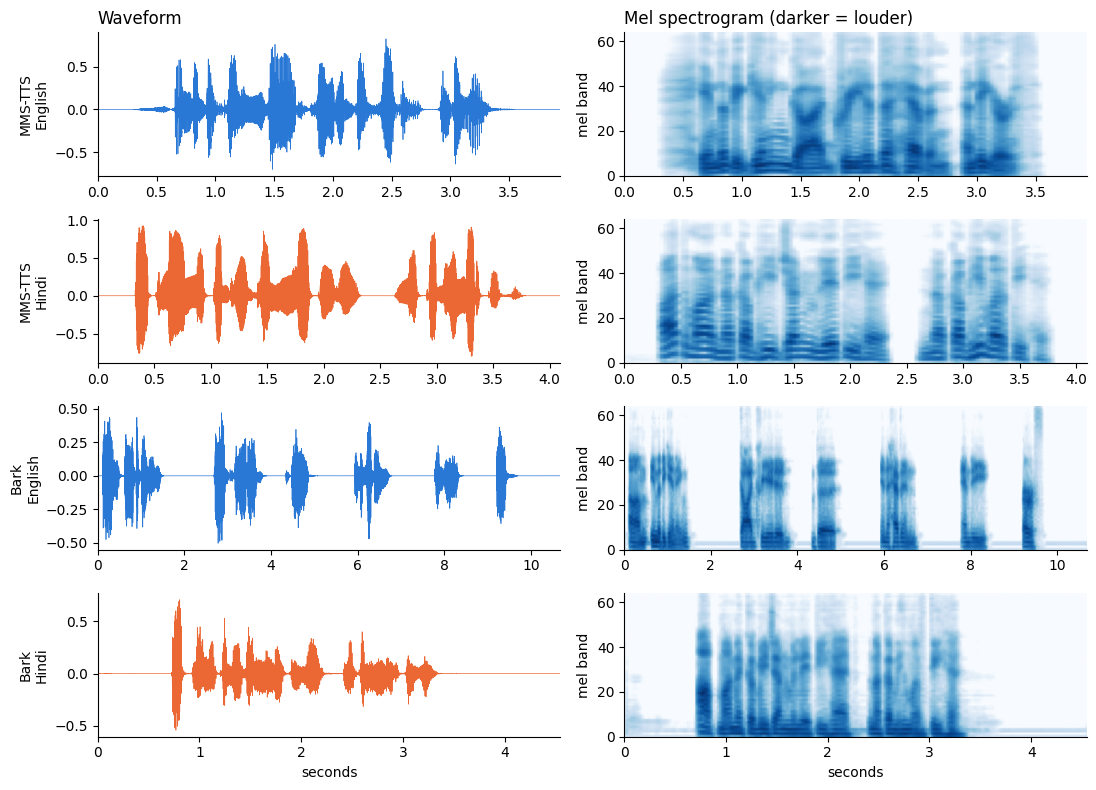

In [26]:
# 1. Waveform and mel spectrogram of the first verse, per TTS model and language
fig, axes = plt.subplots(len(demo_audio), 2, figsize=(11, 2.0 * len(demo_audio)), squeeze=False)
for row, ((tts_name, lang), (audio, sr)) in enumerate(demo_audio.items()):
    t = np.arange(len(audio)) / sr
    axes[row, 0].plot(t, audio, lw=0.5, color=LANG_COLOR[lang])
    axes[row, 0].set_ylabel(f"{tts_name}\n{LANG_NAME[lang]}")
    axes[row, 0].set_xlim(0, t[-1])
    mel = librosa.power_to_db(librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=64), ref=np.max)
    axes[row, 1].imshow(mel, origin="lower", aspect="auto", cmap="Blues", extent=[0, t[-1], 0, 64])
    axes[row, 1].set_ylabel("mel band")
axes[0, 0].set_title("Waveform", loc="left")
axes[0, 1].set_title("Mel spectrogram (darker = louder)", loc="left")
axes[-1, 0].set_xlabel("seconds"); axes[-1, 1].set_xlabel("seconds")
plt.tight_layout()
plt.show()


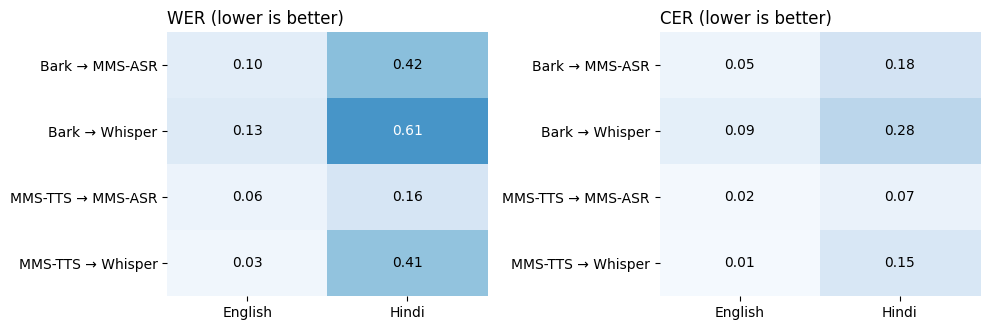

In [27]:
# 2. WER and CER heatmaps (rows: TTS → STT pairing, columns: language)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, metric in zip(axes, ["WER", "CER"]):
    piv = quality_df[metric].unstack("lang")
    labels = [f"{t} → {s}" for t, s in piv.index]
    ax.imshow(piv.values, cmap="Blues", vmin=0, vmax=max(1.0, float(np.nanmax(piv.values))), aspect="auto")
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    color="white" if v > 0.5 * max(1.0, np.nanmax(piv.values)) else "black")
    ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels([LANG_NAME[c] for c in piv.columns])
    ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(labels)
    ax.set_title(f"{metric} (lower is better)", loc="left")
    ax.spines[:].set_visible(False)
plt.tight_layout()
plt.show()


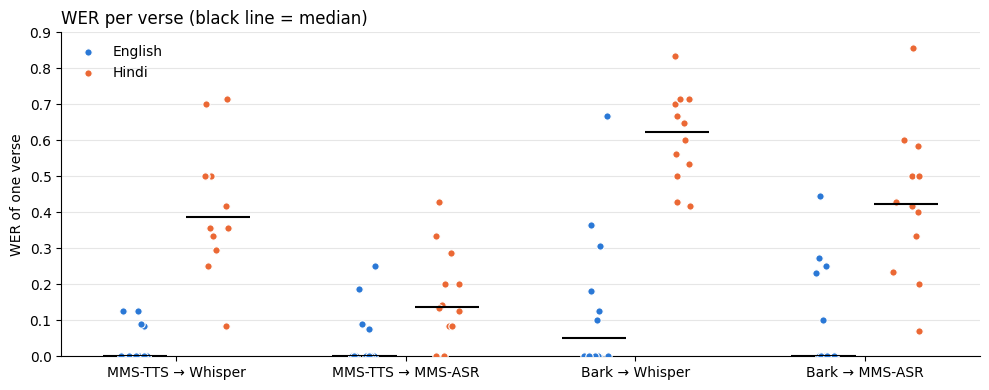

,lang,pair,ref,verse_wer
75,hin,Bark → MMS-ASR,Gita 2.14,0.86
78,hin,Bark → Whisper,Gita 2.48,0.83
26,hin,MMS-TTS → Whisper,Gita 2.14,0.71
80,hin,Bark → Whisper,Gita 2.50,0.71
74,hin,Bark → Whisper,Gita 2.14,0.71


In [28]:
# 3. Per-verse WER: one dot per verse, per pairing
import jiwer

records_df["verse_wer"] = [jiwer.wer(normalize(o), normalize(h)) if normalize(h) else 1.0
                           for o, h in zip(records_df["original"], records_df["transcribed"])]
pairs = list(dict.fromkeys(records_df["pair"]))
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(10, 4))
for lang, offset in [("eng", -0.18), ("hin", 0.18)]:
    for k, pair in enumerate(pairs):
        vals = records_df[(records_df["pair"] == pair) & (records_df["lang"] == lang)]["verse_wer"].values
        xs = k + offset + rng.uniform(-0.06, 0.06, len(vals))
        ax.scatter(xs, vals, s=28, color=LANG_COLOR[lang], edgecolor="white", linewidth=0.8, zorder=3,
                   label=LANG_NAME[lang] if k == 0 else None)
        ax.hlines(np.median(vals), k + offset - 0.14, k + offset + 0.14, color="black", lw=1.5, zorder=4)
ax.set_xticks(range(len(pairs))); ax.set_xticklabels(pairs)
ax.set_ylabel("WER of one verse"); ax.set_ylim(bottom=0)
ax.set_title("WER per verse (black line = median)", loc="left")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", color="#e6e6e6", zorder=0)
plt.tight_layout()
plt.show()

worst = (records_df.sort_values("verse_wer", ascending=False)
         [["lang", "pair", "ref", "verse_wer"]].head(5).round(2))
worst


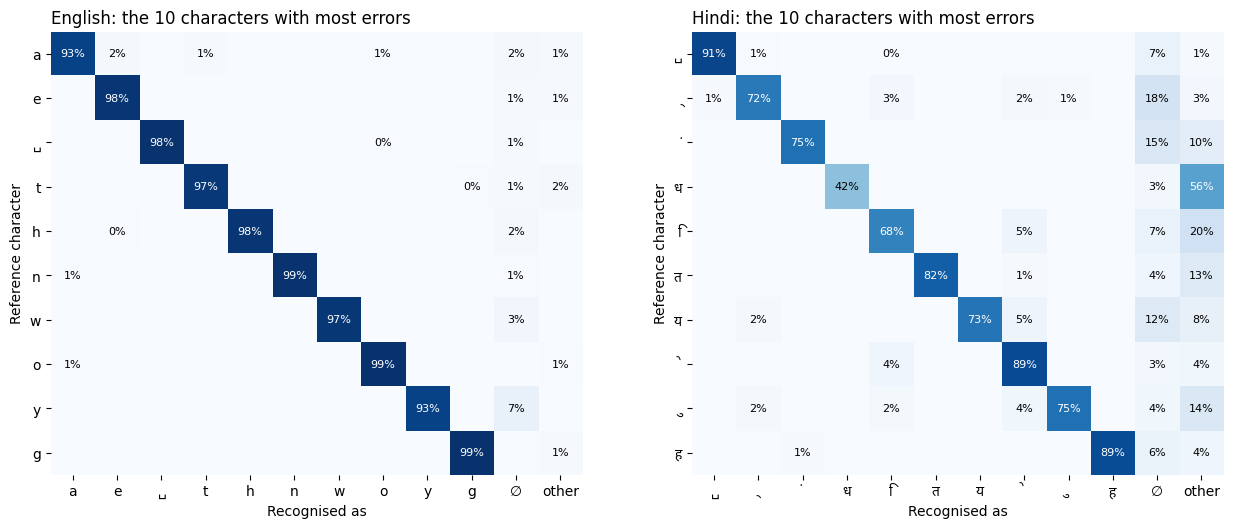

∅ = character not recognised (deleted); ␣ = space; each row sums to 100%.


In [29]:
# 4. Character confusion matrix (all four pairings together), one panel per language
def char_pairs(ref, hyp):
    """Align two strings and return (reference char, recognised char) pairs; '∅' = character missing."""
    out = []
    for tag, i1, i2, j1, j2 in SequenceMatcher(None, ref, hyp, autojunk=False).get_opcodes():
        if tag == "equal":
            out += [(c, c) for c in ref[i1:i2]]
        elif tag == "delete":
            out += [(c, "∅") for c in ref[i1:i2]]
        elif tag == "replace":
            a, b = ref[i1:i2], hyp[j1:j2]
            out += list(zip(a, b)) + [(c, "∅") for c in a[len(b):]]
        # 'insert' has no reference character, so it is not counted here
    return out

def char_confusion(lang, top=10):
    counts = Counter()
    for o, h in zip(records_df[records_df["lang"] == lang]["original"],
                    records_df[records_df["lang"] == lang]["transcribed"]):
        counts.update(char_pairs(normalize(o).replace(" ", "␣"), normalize(h).replace(" ", "␣")))
    errors = Counter()
    for (r, h), n in counts.items():
        if r != h:
            errors[r] += n
    rows = [c for c, _ in errors.most_common(top)]          # reference characters with most errors
    cols = rows + ["∅", "other"]
    mat = np.zeros((len(rows), len(cols)))
    for i, r in enumerate(rows):
        for (rr, h), n in counts.items():
            if rr == r:
                mat[i, cols.index(h) if h in cols else cols.index("other")] += n
    return rows, cols, mat / mat.sum(axis=1, keepdims=True), mat

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, lang in zip(axes, ["eng", "hin"]):
    rows, cols, share, mat = char_confusion(lang)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(rows)):
        for j in range(len(cols)):
            if mat[i, j]:
                ax.text(j, i, f"{share[i, j]:.0%}", ha="center", va="center", fontsize=8,
                        color="white" if share[i, j] > 0.5 else "black")
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols)
    ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows)
    ax.set_xlabel("Recognised as"); ax.set_ylabel("Reference character")
    ax.set_title(f"{LANG_NAME[lang]}: the 10 characters with most errors", loc="left")
    ax.spines[:].set_visible(False)
plt.tight_layout()
plt.show()
print("∅ = character not recognised (deleted); ␣ = space; each row sums to 100%.")


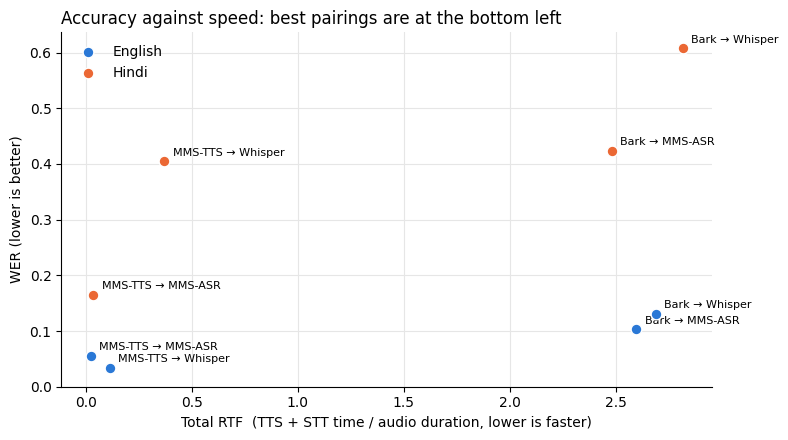

In [30]:
# 5. Accuracy against speed: WER against total real-time factor (TTS RTF + STT RTF)
fig, ax = plt.subplots(figsize=(8, 4.5))
seen = set()
for (lang, tts_name, stt_name), row in quality_df.iterrows():
    rtf = tts_rtf.loc[tts_name, lang] + stt_rtf.loc[stt_name, lang]
    ax.scatter(rtf, row["WER"], s=60, color=LANG_COLOR[lang], edgecolor="white", linewidth=1, zorder=3,
               label=LANG_NAME[lang] if lang not in seen else None)
    seen.add(lang)
    ax.annotate(f"{tts_name} → {stt_name}", (rtf, row["WER"]), xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("Total RTF  (TTS + STT time / audio duration, lower is faster)")
ax.set_ylabel("WER (lower is better)")
ax.set_ylim(bottom=0)
ax.set_title("Accuracy against speed: best pairings are at the bottom left", loc="left")
ax.grid(color="#e6e6e6", zorder=0)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


## Conclusion

This notebook demonstrated:

- **4 sophisticated models** via `transformers`: MMS-TTS and Bark (text-to-speech),
  Whisper and MMS-ASR (speech-to-text), tested in all 4 TTS → STT pairings
- **2 languages**: English and Hindi
- **4 metrics**: WER, CER, BLEU (round-trip intelligibility) and RTF (speed)
- **Corpus**: 12 King James Bible verses (English) and 12 Bhagavad Gita verses (Hindi),
  each traceable to its source reference

Because each pairing mixes one synthesiser with one recogniser, a high error rate can
come from either side. Compare pairings that share a TTS model (same audio, different
STT) to judge the recognisers, and pairings that share an STT model (same recogniser,
different audio) to judge the synthesisers.
